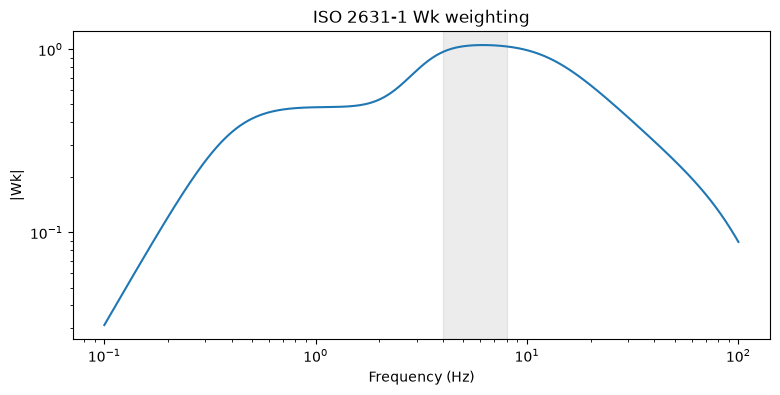

[0.48247335 0.96718105 1.03636622 0.7686991 ]


In [2]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2
from src.comfort import wk_coefficients, wk_gain
import numpy as np
import matplotlib.pyplot as plt

f = np.logspace(-1, 2, 500)
gain = wk_gain(f)

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(f, gain)
ax.axvspan(4, 8, color = 'grey', alpha = 0.15)   #maximum zone of human sensitivity
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('|Wk|')
ax.set_title('ISO 2631-1 Wk weighting')
plt.show()

print(wk_gain([1, 4, 8, 16]))

In [3]:
from src.comfort import weighted_rms
import pandas as pd

data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

for side,  (signals, windows) in data.items():
    for pos in ['dashboard', 'above_suspension']:
        col = f'acc_z_{pos}_filt'
        aw, rms = {}, {}
        for w in windows[windows['valid']].index:
            x = signals.loc[signals['window'] == w, col].to_numpy()
            aw[w] = weighted_rms(x)
            rms[w] = np.sqrt(np.mean(x**2))
        windows[f'aw_{pos}'] = pd.Series(aw)
        windows[f'rms_{pos}'] = pd.Series(rms)

display(data['left'][1][data['left'][1]['valid']].head())

,t_start,n_rows,n_surfaces,surface,speed_mean,speed_std,has_invalid,valid,trip,side,aw_dashboard,rms_dashboard,aw_above_suspension,rms_above_suspension
window,,,,,,,,,,,,,,
22,110.0,500,1,asphalt_road,13.081990,0.784259,False,True,PVS1,left,0.347617,0.491259,0.492140,0.632972
23,115.0,500,1,asphalt_road,16.340947,0.479416,False,True,PVS1,left,0.367984,0.563944,0.598589,0.776247
24,120.0,500,1,asphalt_road,17.056375,0.445707,False,True,PVS1,left,0.486833,0.627646,0.672800,0.802604
25,125.0,500,1,asphalt_road,18.653855,0.408861,False,True,PVS1,left,0.528991,0.639719,0.603997,0.783878
27,135.0,500,1,asphalt_road,19.807342,0.586014,False,True,PVS1,left,0.924381,1.091045,1.272086,1.400284


In [4]:
for side, (signals, windows) in data.items():
    print(side)
    display(windows[windows['valid']].groupby('surface')[['aw_dashboard', 'rms_dashboard']].agg(['mean', 'std']).round(3))

left


aw_dashboard        rms_dashboard       
                         mean    std          mean    std
surface                                                  
asphalt_road            0.576  0.141         0.823  0.160
cobblestone_road        1.309  0.351         1.968  0.454
dirt_road               1.276  0.336         1.770  0.361

right


aw_dashboard        rms_dashboard       
                         mean    std          mean    std
surface                                                  
asphalt_road            0.589  0.144         0.836  0.165
cobblestone_road        1.307  0.363         1.948  0.457
dirt_road               1.277  0.331         1.778  0.372

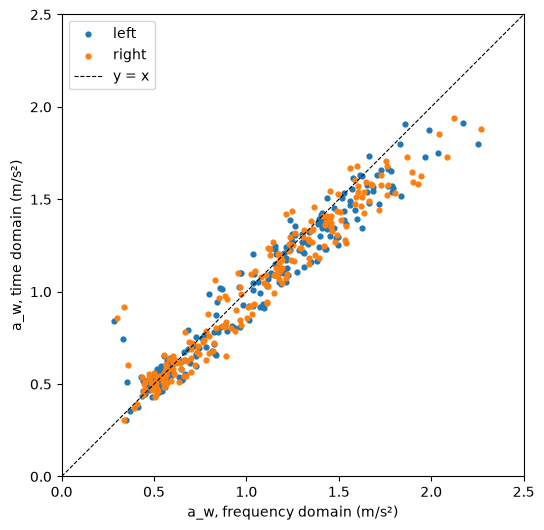

In [5]:
from src.comfort import apply_wk, crest_factor, vdv

for side, (signals, windows) in data.items():
    signals['acc_z_dashboard_wk'] = apply_wk(signals['acc_z_dashboard_filt'].to_numpy())

    aw_t, cf, dose = {}, {}, {}
    for w in windows[windows['valid']].index:
        x = signals.loc[signals['window'] == w, 'acc_z_dashboard_wk'].to_numpy()
        aw_t[w] = np.sqrt(np.mean(x**2))
        cf[w] = crest_factor(x)
        dose[w] = vdv(x)
    windows['aw_dashboard_time'] = pd.Series(aw_t)
    windows['cf_dashboard'] = pd.Series(cf)
    windows['vdv_dashboard'] = pd.Series(dose)

fig, ax = plt.subplots(figsize=(6, 6))
for side, (signals, windows) in data.items():
    ax.scatter(windows['aw_dashboard'], windows['aw_dashboard_time'], s=12, label=side)

lim = [0, 2.5]
ax.plot(lim, lim, 'k--', lw=0.8, label='y = x')
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel('a_w, frequency domain (m/s²)')
ax.set_ylabel('a_w, time domain (m/s²)')
ax.set_aspect('equal')
ax.legend()
plt.show()

In [6]:
for side, (signals, windows) in data.items():
    print(side)
    display(windows[windows['valid']].groupby('surface')[['aw_dashboard', 'aw_dashboard_time', 'cf_dashboard', 'vdv_dashboard']].agg(['mean', 'std', 'max']).round(3))
    print('Windows with crest factor > 9:', (windows[windows['valid']]['cf_dashboard'] > 9).sum())

left


aw_dashboard               aw_dashboard_time                \
                         mean    std    max              mean    std    max   
surface                                                                       
asphalt_road            0.576  0.141  0.964             0.567  0.122  1.104   
cobblestone_road        1.309  0.351  2.173             1.239  0.313  1.913   
dirt_road               1.276  0.336  2.252             1.230  0.264  1.802   

                 cf_dashboard               vdv_dashboard                
                         mean    std    max          mean    std    max  
surface                                                                  
asphalt_road            3.462  0.723  7.452         1.155  0.317  2.415  
cobblestone_road        3.324  0.482  4.899         2.458  0.624  4.169  
dirt_road               3.374  0.488  4.735         2.455  0.556  3.821

Windows with crest factor > 9: 0
right


aw_dashboard               aw_dashboard_time                \
                         mean    std    max              mean    std    max   
surface                                                                       
asphalt_road            0.589  0.144  0.967             0.579  0.127  1.101   
cobblestone_road        1.307  0.363  2.123             1.232  0.313  1.943   
dirt_road               1.277  0.331  2.268             1.239  0.260  1.882   

                 cf_dashboard               vdv_dashboard                
                         mean    std    max          mean    std    max  
surface                                                                  
asphalt_road            3.512  0.756  7.777         1.186  0.362  3.104  
cobblestone_road        3.345  0.511  4.820         2.455  0.634  3.906  
dirt_road               3.343  0.450  4.571         2.471  0.544  3.664

Windows with crest factor > 9: 0


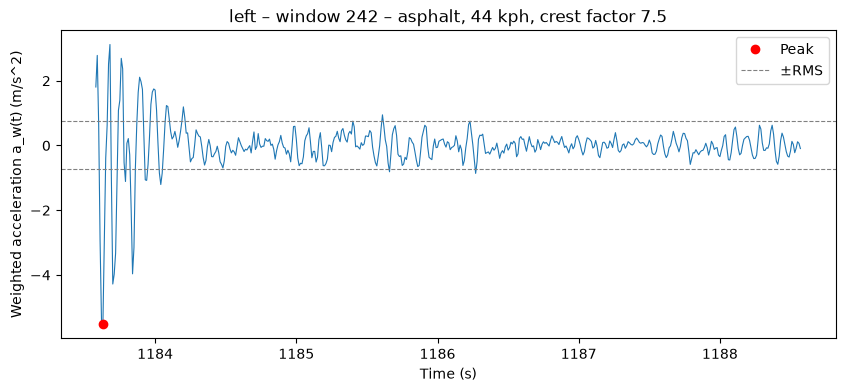

left – peak at t = 1183.6 s


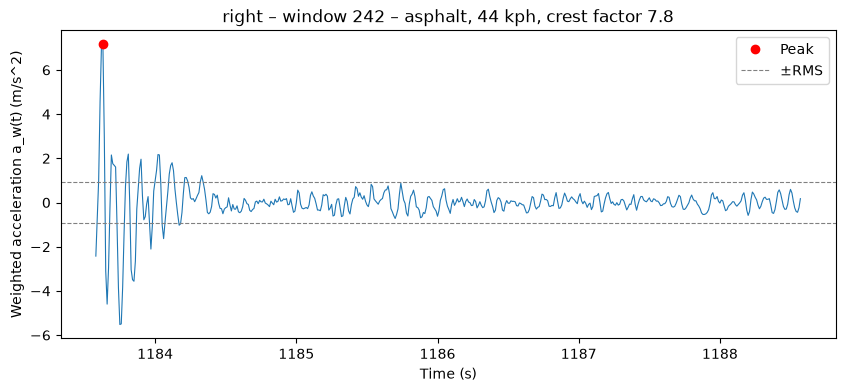

right – peak at t = 1183.6 s


In [7]:
for side, (signals, windows) in data.items():
    v = windows[windows['valid'] & (windows['surface'] == 'asphalt_road')]
    w_max = v['cf_dashboard'].idxmax()
    seg = signals[signals['window'] == w_max]

    x = seg['acc_z_dashboard_wk'].to_numpy()
    i_peak = np.argmax(np.abs(x))
    rms = windows.loc[w_max, 'aw_dashboard_time']

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(seg['t'], x, lw=0.8)
    ax.plot(seg['t'].iloc[i_peak], x[i_peak], 'ro', label='Peak')
    ax.axhline(rms, c='grey', ls='--', lw=0.8, label='±RMS')
    ax.axhline(-rms, c='grey', ls='--', lw=0.8)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Weighted acceleration a_w(t) (m/s^2)')
    ax.set_title(f"{side} – window {w_max} – asphalt, {windows.loc[w_max, 'speed_mean'] * 3.6:.0f} kph, "
                 f"crest factor {windows.loc[w_max, 'cf_dashboard']:.1f}")
    ax.legend()
    plt.show()

    print(side, '– peak at t =', round(seg['t'].iloc[i_peak], 1), 's')

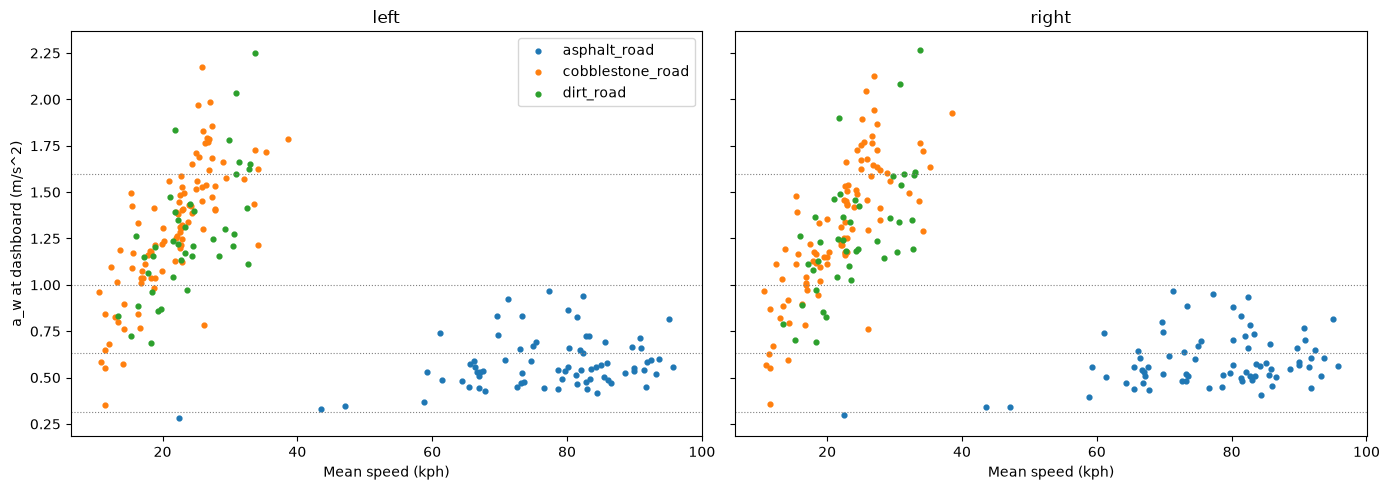

In [8]:
surfaces = ['asphalt_road', 'cobblestone_road', 'dirt_road']

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (side, (signals, windows)) in zip(axes, data.items()):
    v = windows[windows['valid']]
    for surf in surfaces:
        s = v[v['surface'] == surf]
        ax.scatter(s['speed_mean'] * 3.6, s['aw_dashboard'], s=12, label=surf)
    for level in [0.315, 0.63, 1.0, 1.6]:
        ax.axhline(level, c='grey', ls=':', lw=0.8)
    ax.set_title(side)
    ax.set_xlabel('Mean speed (kph)')

axes[0].set_ylabel('a_w at dashboard (m/s^2)')
axes[0].legend()
plt.tight_layout()
plt.show()

In [9]:
data['left'][1].loc[240:243, ['surface', 't_start', 'speed_mean', 'valid']]

,surface,t_start,speed_mean,valid
window,,,,
240,cobblestone_road,1175.61,10.718078,True
241,cobblestone_road,1180.61,10.997824,False
242,asphalt_road,1183.58,12.083893,True
243,asphalt_road,1188.58,10.544881,False


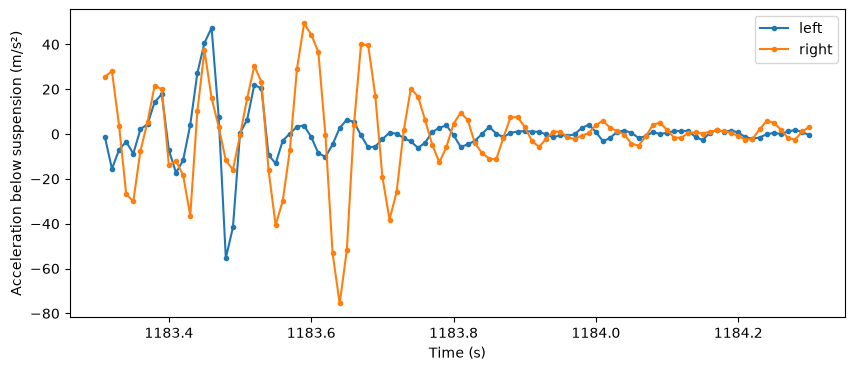

In [10]:
t0, t1 = 1183.3, 1184.3
fig, ax = plt.subplots(figsize=(10, 4))
for side, (signals, windows) in data.items():
    seg = signals[(signals['t'] >= t0) & (signals['t'] <= t1)]
    ax.plot(seg['t'], seg['acc_z_below_suspension_filt'], marker='.', label=side)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Acceleration below suspension (m/s²)')
ax.legend()
plt.show()

## Part 5 – Conclusions (PVS 1)

1. **Weighted acceleration (ISO 2631-1, Wk, dashboard):** mean a_w is 0.58–0.59 m/s^2 on asphalt, 1.31 m/s^2 on cobblestone and 1.28 m/s² on dirt (left and right sides consistent). According to the ISO 2631-1 comfort scale, asphalt falls in the "a little uncomfortable" to "fairly uncomfortable" range, while cobblestone and dirt fall in the "uncomfortable" to "very uncomfortable" range, despite being driven at much lower speeds.
2. **Effect of the frequency weighting:** a_w is ~30 % lower than the unweighted RMS (a_w / RMS ≈ 0.70 on asphalt, 0.72 on dirt, 0.67 on cobblestone), since a large share of the energy lies outside the 4–8 Hz range of maximum human sensitivity. Cobblestone shows a higher unweighted RMS than dirt (1.97 vs 1.77 m/s^2), but after weighting they are almost equal (1.31 vs 1.28 m/s^2): the additional energy of cobblestone lies at frequencies with low weighting (body mode at ~1.5 Hz and the ~35 Hz dashboard peak).
3. **Calculation methods:** a_w obtained in the frequency domain (PSD × |Wk|²) and in the time domain (digital Wk filter, bilinear transform) agree within ±10–15 %. Differences are attributed to the Hann window in the PSD estimate, which down-weights events near window edges, and to the causal filter shifting energy between adjacent windows.
4. **Crest factor:** the mean crest factor is 3.3–3.5 on all surfaces, typical of random vibration. No window exceeds the ISO 2631-1 threshold of 9, so the RMS-based evaluation is valid. Cobblestone and dirt show uniform, continuous roughness (maximum crest factor 4.6–4.9), whereas asphalt is mostly smooth with isolated events (higher crest factor variability).
5. **Vibration dose value:** VDV per 5 s window is ~2.46 m/s^1.75 on cobblestone and dirt and ~1.17 m/s^1.75 on asphalt, consistent with the a_w ranking. Since VDV is cumulative, these window values are not comparable with daily exposure limits.
6. **Speed:** on cobblestone and dirt, a_w increases strongly with speed, from ~0.6–1.0 m/s^2 at 10–15 kph to 1.5–2.2 m/s^2 at 30–35 kph, exceeding 1.6 m/s^2 in many windows above ~25 km/h. On asphalt there is no clear trend between 60 and 95 kph (a_w ≈ 0.45–0.95 m/s^2).
7. **Surface transition event:** the highest crest factor on asphalt (7.5–7.8, window 242) corresponds to the cobblestone-to-asphalt transition at the start of the window, not to the asphalt surface itself. The left wheel hits the edge ~0.15 s before the right wheel (≈1.8 m at ~12 m/s), indicating an angled crossing that excites body roll (opposite-sign peaks at the left and right dashboard). The wheel oscillation after the impact (~13 Hz) matches the wheel-hop frequency identified in Part 3. This event also produced the highest acceleration recorded in the trip (75.3 m/s^2, right side, close to the +-78.5 m/s^2 sensor range).
8. **Limitations:** measurements are taken at the dashboard, not at the seat, so the seat's own filtering is not included and a_w is an indicator of cabin vibration rather than an ISO-compliant comfort assessment. Only the vertical axis is evaluated, and the analysis is limited to 0.5–40 Hz (the standard covers up to 80 Hz). Speed and surface are confounded in this trip. Windows starting at a surface change can include transition events, as in window 242.

In [11]:
for side, (signals, windows) in data.items():
    windows.to_csv(f'../data/processed/windows_metrics_PVS1_{side}.csv')